# 02 · Recreación del análisis del artículo

Se replica el procedimiento de los autores en el mismo orden (CRISP-DM):

1. Preparación de datos: limpieza, atípicos (IQR + winsorización), Label Encoding.
2. Selección de variables con Random Forest (Figura 8).
3. **Fase no supervisada:** top 10 variables → RobustScaler → PCA (≥ 90% varianza) → K-Means (k = 3) = etiqueta `RIESGO_DE_MOROSIDAD`.
4. **Fase supervisada:** 80/20 estratificado, SMOTE solo en entrenamiento, RandomForest, GradientBoosting, AdaBoost y VotingClassifier (soft) con los hiperparámetros del paper.
5. Evaluación con las 9 métricas, validación cruzada estratificada k = 5 y matrices de confusión.
6. Pruebas de estrés (los 4 escenarios del paper).
7. Comparación con las Tablas 1, 2 y 3.

> Los experimentos lentos se guardan en `results/`. Para recalcular todo, cambia `RECALCULAR = True` (≈ 40 min en un portátil de 2 núcleos).

In [2]:
   %pip install imbalanced-learn

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.3 MB 13.9 MB/s eta 0:00:01
   ---------- ----------------------------- 2.1/8.3 MB 4.7 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.3 MB 3.8 MB/s eta 0:00:02
   ------------- -------------------------- 2.9/8.3 MB 3.4 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.3 MB 3.1 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.3 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.3 MB 2.9 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.3 MB 2.9 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.3 MB 2.7 MB/s eta 0:00:02
   --------------------------- ------------ 5.8/8.3 MB 2.7 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.3 MB 2.7 MB/s eta 0:00:01
   --------------------

In [3]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
from preparacion import (limpiar, outliers_iqr, winsorizar, codificar, importancia_rf, metodo_codo,
                         matriz_clustering, etiquetar_riesgo, PREDICTORAS)
from modelos import entrenar_evaluar, validacion_cruzada, escenarios_estres
from graficos import matrices_confusion, barras_comparacion
from utilidades import cache_csv
import paper

RECALCULAR = False
SEMILLA = 42

## 1 · Preparación de datos

In [4]:
crudo = pd.read_csv("../data/cartera_simulada.csv")
df, reporte = limpiar(crudo)
pd.Series(reporte, name="registros")

inicial           72700
sin_pasivo        70521
sin_negativos     70168
sin_duplicados    69956
Name: registros, dtype: int64

In [5]:
print("Atípicos por IQR (antes de winsorizar):")
outliers_iqr(df).sort_values(ascending=False)

Atípicos por IQR (antes de winsorizar):


V_VENCIDO_INTERESES    11694
V_VENCIDO_ALUMBRADO    10753
V_VENCIDO_ENERGIA      10746
VALOR_DEUDA            10210
MESES_DEUDA             7856
V_VENCIDO_BOMBEROS      7856
VALOR_FACTURACION       7815
VALOR_RECAUDACION       7364
dtype: int64

El paper detecta atípicos con IQR y los trata con **winsorización** sin dar los límites. **Supuesto:** recortar a los percentiles 1 y 99. Recortar a 1,5·IQR destruiría la información de mora, porque más del 85% de los clientes debe 0 meses.

In [6]:
df = codificar(winsorizar(df))
df[PREDICTORAS].describe().T[["min", "50%", "max"]]

,min,50%,max
VALOR_FACTURACION,2.94,14.875,516.6685
VALOR_RECAUDACION,0.00,12.710,464.8735
MESES_DEUDA,0.00,0.000,54.0000
V_VENCIDO_ENERGIA,0.00,0.000,1692.9490
V_VENCIDO_ALUMBRADO,0.00,0.000,171.3500
V_VENCIDO_BOMBEROS,0.00,0.000,27.0000
V_VENCIDO_INTERESES,0.00,0.000,554.0165
VALOR_DEUDA,3.24,21.430,2616.5765
RANGO_VALOR,1.00,2.000,8.0000
RANGO_ANTIGUEDAD,1.00,1.000,6.0000


## 2 · Selección de variables con Random Forest

El paper no dice qué variable objetivo usó para la importancia (aún no existía la etiqueta de riesgo). **Supuesto:** se usa `NIVEL_MOROSIDAD`, la clasificación que la empresa ya tiene.

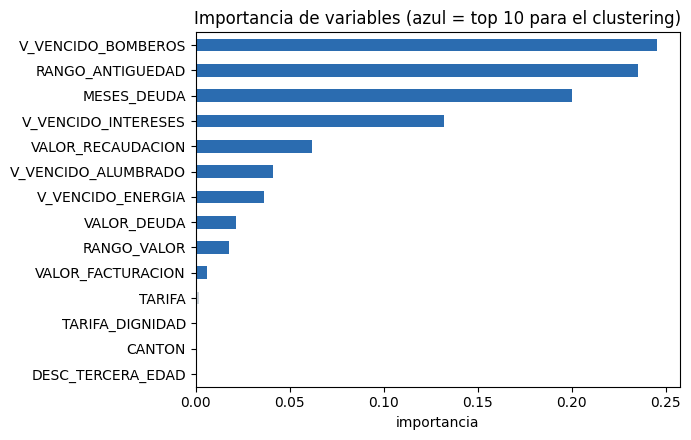

In [7]:
importancia = importancia_rf(df, seed=SEMILLA)
top10 = importancia.index[:10].tolist()

ax = importancia.sort_values().plot.barh(figsize=(7, 4.5), color=["#2b6cb0" if c in top10 else "#cbd2d9" for c in importancia.sort_values().index])
ax.set(title="Importancia de variables (azul = top 10 para el clustering)", xlabel="importancia")
plt.tight_layout(); plt.savefig("../figures/02_importancia_variables.png", dpi=120); plt.show()

## 3 · Fase no supervisada: creación de la etiqueta de riesgo

**Hallazgo de la réplica.** Si se aplica RobustScaler directamente, como describe el paper, el clustering degenera: un solo componente explica casi toda la varianza y un clúster concentra casi todos los clientes. Esto pasa porque la mayoría de clientes tiene 0 en los valores vencidos (mediana e IQR = 0).

In [8]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

X_crudo = matriz_clustering(df, top10, log=False, rango=(25, 75))
pca_crudo = PCA(0.90).fit(X_crudo)
km_crudo = KMeans(3, n_init=10, random_state=SEMILLA).fit(pca_crudo.transform(X_crudo))
print(f"Versión cruda -> componentes: {pca_crudo.n_components_}, "
      f"varianza: {pca_crudo.explained_variance_ratio_.sum():.3f}, "
      f"tamaño de clústeres: {np.round(np.bincount(km_crudo.labels_) / len(df), 3)}")

Versión cruda -> componentes: 1, varianza: 0.999, tamaño de clústeres: [0.966 0.015 0.019]


**Supuesto:** se aplica `log1p` a los montos y RobustScaler con rango intercuantílico 10–90. Ambas son prácticas estándar para datos monetarios con muchos ceros, y acercan la estructura a la que reporta el paper.

Antes de fijar k = 3, el método del codo (como en el paper):

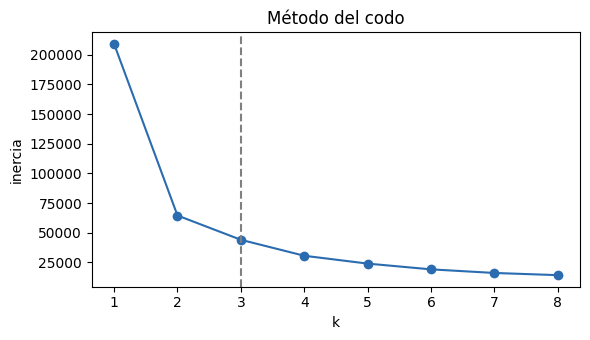

In [9]:
Z_codo = PCA(0.90, random_state=SEMILLA).fit_transform(matriz_clustering(df, top10))
codo = metodo_codo(Z_codo, seed=SEMILLA)
ax = codo.plot(marker="o", figsize=(6, 3.5), color="#2b6cb0")
ax.axvline(3, ls="--", color="gray"); ax.set(title="Método del codo", xlabel="k", ylabel="inercia")
plt.tight_layout(); plt.savefig("../figures/02_codo.png", dpi=120); plt.show()

In [10]:
df["RIESGO_DE_MOROSIDAD"], Z, info = etiquetar_riesgo(df, top10, k=3, seed=SEMILLA)

clustering = pd.DataFrame({
    "Paper": [paper.CLUSTERING["varianza_explicada"], paper.CLUSTERING["silhouette"]],
    "Réplica": [info["varianza_explicada"], info["silhouette"]],
}, index=["Varianza explicada PCA", "Silhouette"])
clustering.to_csv("../results/02_clustering.csv")
print("Componentes PCA:", info["componentes"])
clustering

Componentes PCA: 2


,Paper,Réplica
Varianza explicada PCA,0.9021,0.9393
Silhouette,0.6810,0.5438


In [11]:
perfil = df.groupby("RIESGO_DE_MOROSIDAD").agg(
    clientes=("VALOR_DEUDA", "size"), deuda_media=("VALOR_DEUDA", "mean"),
    meses_mora_medios=("MESES_DEUDA", "mean"), recaudacion_media=("VALOR_RECAUDACION", "mean"))
perfil["proporcion"] = perfil.clientes / perfil.clientes.sum()
perfil.index = ["0 · Bajo", "1 · Medio", "2 · Alto"]
perfil.to_csv("../results/02_perfil_riesgo.csv")
perfil

,clientes,deuda_media,meses_mora_medios,recaudacion_media,proporcion
0 · Bajo,51035,17.9121,0.3013,14.2896,0.7295
1 · Medio,12967,171.6776,1.0726,93.7235,0.1854
2 · Alto,5954,858.0493,23.8139,4.8970,0.0851


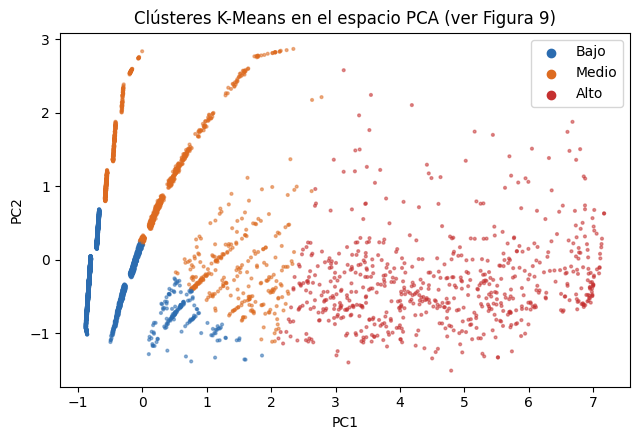

In [12]:
colores = np.array(["#2b6cb0", "#dd6b20", "#c53030"])
muestra = np.random.default_rng(SEMILLA).choice(len(Z), 8000, replace=False)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(Z[muestra, 0], Z[muestra, 1], c=colores[df.RIESGO_DE_MOROSIDAD.values[muestra]], s=4, alpha=0.5)
for i, n in enumerate(["Bajo", "Medio", "Alto"]):
    ax.scatter([], [], c=colores[i], label=n)
ax.set(title="Clústeres K-Means en el espacio PCA (ver Figura 9)", xlabel="PC1", ylabel="PC2"); ax.legend()
plt.tight_layout(); plt.savefig("../figures/02_clusters_pca.png", dpi=120); plt.show()

## 4 · Fase supervisada

Variables explicativas: los montos, meses de deuda, componentes del valor vencido, rangos y categóricas codificadas (las que el paper menciona en la fase supervisada y en SHAP/LIME).

| Modelo | Hiperparámetros (paper) |
|---|---|
| RandomForest | n_estimators=150, max_depth=12, min_samples_split=5, min_samples_leaf=3, max_features="sqrt", class_weight="balanced" |
| GradientBoosting | n_estimators=200, learning_rate=0.05, subsample=0.8 · *supuesto:* max_depth=3, min_samples_split=10 |
| AdaBoost | n_estimators=150, learning_rate=0.1 |
| VotingClassifier | votación suave de los tres anteriores, pesos iguales (*supuesto*: el paper no da los pesos) |

In [13]:
X, y = df[PREDICTORAS], df["RIESGO_DE_MOROSIDAD"]
df[PREDICTORAS + ["RIESGO_DE_MOROSIDAD"]].to_csv("../data/cartera_etiquetada.csv", index=False)

resultados, matrices, modelos = entrenar_evaluar(X, y, seed=SEMILLA)
resultados.to_csv("../results/02_metricas_replica.csv")
resultados

,Accuracy,Balanced Accuracy,F1 Macro,Precision Macro,Recall Macro,Cohen's Kappa,Matthews Corrcoef,AUC ROC (OVR),PR AUC
RandomForest,0.9981,0.9978,0.9970,0.9961,0.9978,0.9955,0.9955,1.0000,1.0000
GradientBoosting,0.9984,0.9984,0.9975,0.9966,0.9984,0.9963,0.9963,1.0000,1.0000
AdaBoost,0.9789,0.9842,0.9706,0.9580,0.9842,0.9515,0.9522,0.9995,0.9983
VotingClassifier,0.9985,0.9985,0.9976,0.9967,0.9985,0.9965,0.9965,1.0000,1.0000


### Validación cruzada estratificada k = 5 (Tabla 1)

In [14]:
cv = cache_csv("../results/02_validacion_cruzada.csv", validacion_cruzada, RECALCULAR, X=X, y=y, seed=SEMILLA)
tabla1 = pd.DataFrame({"Accuracy (test)": resultados["Accuracy"], "CV Accuracy": cv["CV Accuracy"],
                       "CV Std": cv["CV Std"], "CV Accuracy paper": paper.TABLA_1_CV})
tabla1

,Accuracy (test),CV Accuracy,CV Std,CV Accuracy paper
RandomForest,0.9981,0.9976,0.0003,0.999
GradientBoosting,0.9984,0.9979,0.0003,0.999
AdaBoost,0.9789,0.9801,0.0011,0.983
VotingClassifier,0.9985,0.9980,0.0004,0.999


### Matrices de confusión (Figura 12)

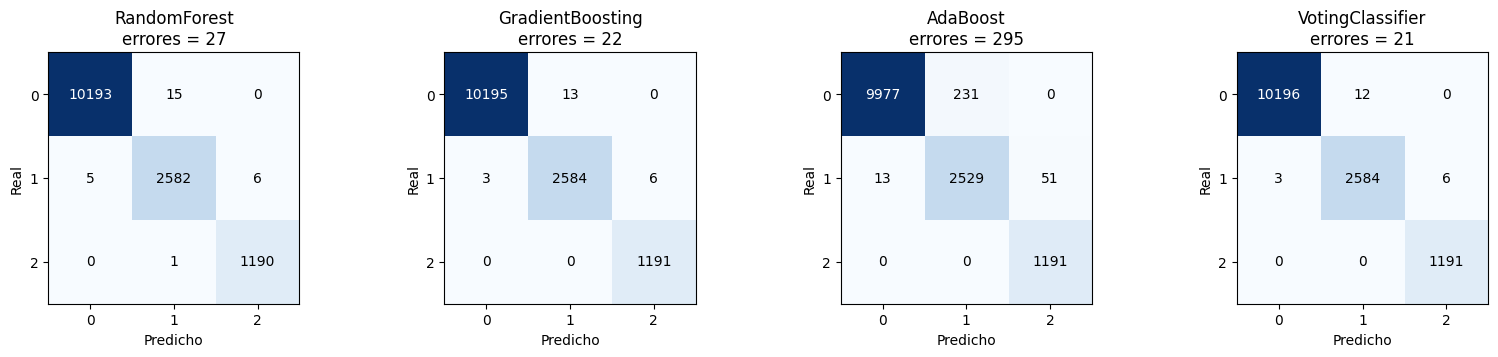

In [15]:
matrices_confusion(matrices, "../figures/02_matrices_confusion.png")

## 5 · Pruebas de estrés (Tabla 3)

Mismos 4 escenarios del paper. **Supuesto:** el ruido σ = 0,3 se aplica como ruido gaussiano proporcional a la desviación estándar de cada variable.

In [16]:
estres = cache_csv("../results/02_estres.csv", escenarios_estres, RECALCULAR, X=X, y=y, seed=SEMILLA)
estres.pivot(index="Modelo", columns="Escenario", values="F1 Macro")[paper.TABLA_3_F1.columns]

Escenario,Base (original),Ruido moderado (σ=0.3),Reducción clase 2 al 50%,Eliminación aleatoria del 40%
Modelo,,,,
AdaBoost,0.9706,0.9092,0.9664,0.9710
GradientBoosting,0.9975,0.9239,0.9967,0.9969
RandomForest,0.9970,0.9281,0.9956,0.9952
VotingClassifier,0.9976,0.9264,0.9968,0.9971


## 6 · Comparación con el artículo (Tabla 2)

In [17]:
comparacion = pd.concat({"Paper": paper.TABLA_2, "Réplica": resultados[paper.COLS]}, axis=1)
diferencia = (resultados[paper.COLS] - paper.TABLA_2).round(4)
comparacion.to_csv("../results/02_comparacion_paper.csv")
print("Diferencia (réplica − paper):")
diferencia

Diferencia (réplica − paper):


,Accuracy,Balanced Accuracy,F1 Macro,Precision Macro,Recall Macro,Cohen's Kappa,Matthews Corrcoef,AUC ROC (OVR),PR AUC
RandomForest,0.0016,-0.0002,0.0054,0.0108,-0.0002,0.0082,0.0081,-0.0000,0.0002
GradientBoosting,0.0002,-0.0003,0.0018,0.0039,-0.0003,0.0028,0.0028,-0.0000,-0.0000
AdaBoost,-0.0056,0.0037,0.0116,0.0176,0.0037,0.0065,0.0063,-0.0002,0.0002
VotingClassifier,0.0002,-0.0005,0.0017,0.0040,-0.0005,0.0027,0.0027,-0.0000,0.0001


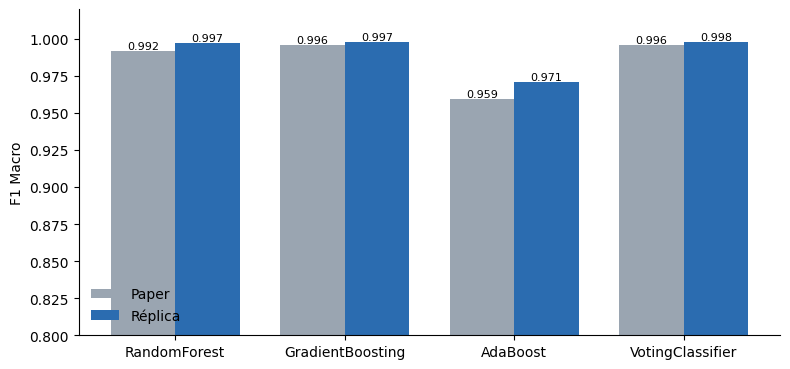

In [18]:
barras_comparacion(pd.DataFrame({"Paper": paper.TABLA_2["F1 Macro"], "Réplica": resultados["F1 Macro"]}),
                   "F1 Macro", "../figures/02_comparacion_f1.png")

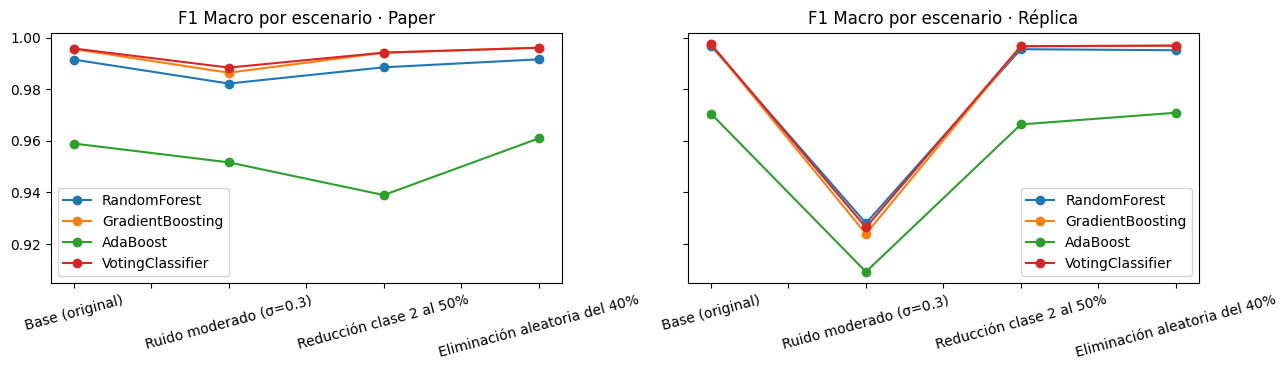

In [19]:
f1_estres = estres.pivot(index="Modelo", columns="Escenario", values="F1 Macro")[paper.TABLA_3_F1.columns]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (titulo, tabla) in zip(axes, [("Paper", paper.TABLA_3_F1), ("Réplica", f1_estres)]):
    tabla.loc[paper.TABLA_3_F1.index].T.plot(ax=ax, marker="o")
    ax.set(title=f"F1 Macro por escenario · {titulo}", xlabel="")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("../figures/02_estres_f1.png", dpi=120); plt.show()

## Lectura de resultados

- **Lo que se recrea:** el orden de los modelos y la conclusión principal (GradientBoosting y VotingClassifier arriba, AdaBoost el más débil), las métricas casi perfectas y la robustez ante los escenarios de estrés.
- **Por qué las métricas son tan altas (aquí y en el paper):** la etiqueta sale de un K-Means sobre las mismas variables que luego usa el clasificador. El modelo supervisado aprende a reproducir las fronteras del clustering, que son casi lineales en el espacio PCA, no a predecir un comportamiento futuro de pago.
- **Diferencias esperables:** proporción de clases (el paper no la reporta), silhouette y varianza del PCA dependen de los supuestos de simulación y del preprocesamiento (log1p + RobustScaler 10–90).

La extensión experimental (notebook 03) pone a prueba precisamente esta dependencia.